In [20]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
import warnings
warnings.filterwarnings('ignore')

In [2]:
filepath = "../data/interim/customer_churn_clean.csv"  
df = pd.read_csv(filepath)

In [3]:
df.shape

(7043, 20)

In [4]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12, 'axes.labelsize': 12, 'axes.titlesize': 14})

Feature: tenure          | Skewness:   0.24 -> Symmetric Distribution (Ideal)


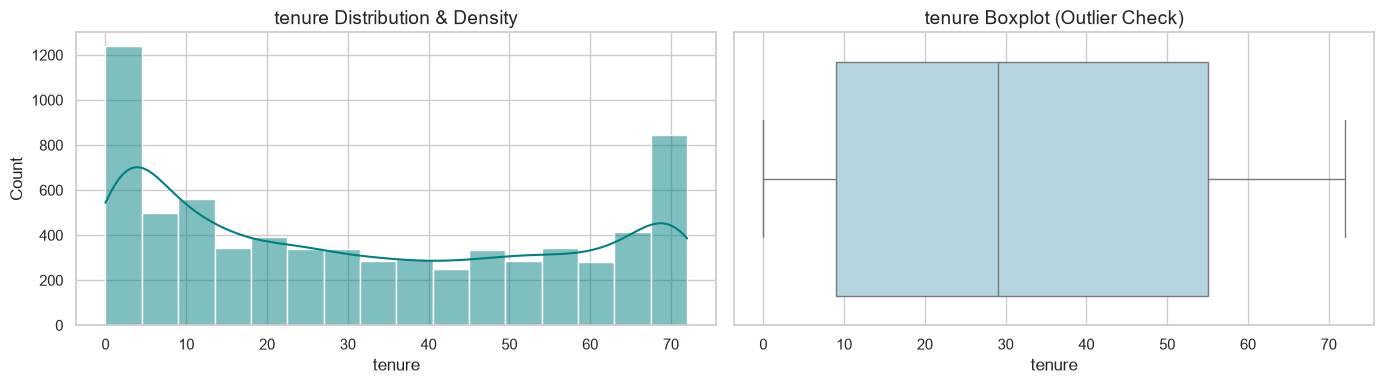

Feature: MonthlyCharges  | Skewness:  -0.22 -> Symmetric Distribution (Ideal)


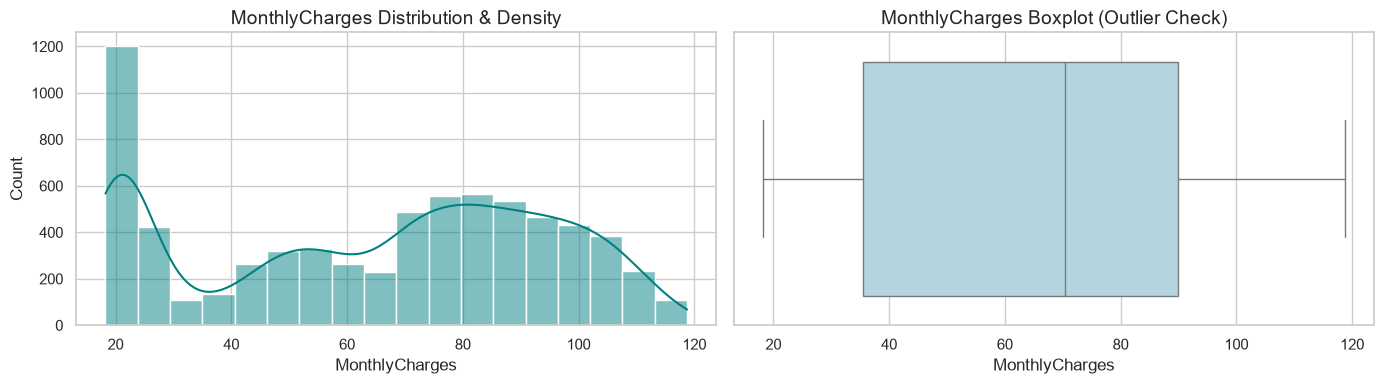

Feature: TotalCharges    | Skewness:   0.96 -> Moderately Skewed


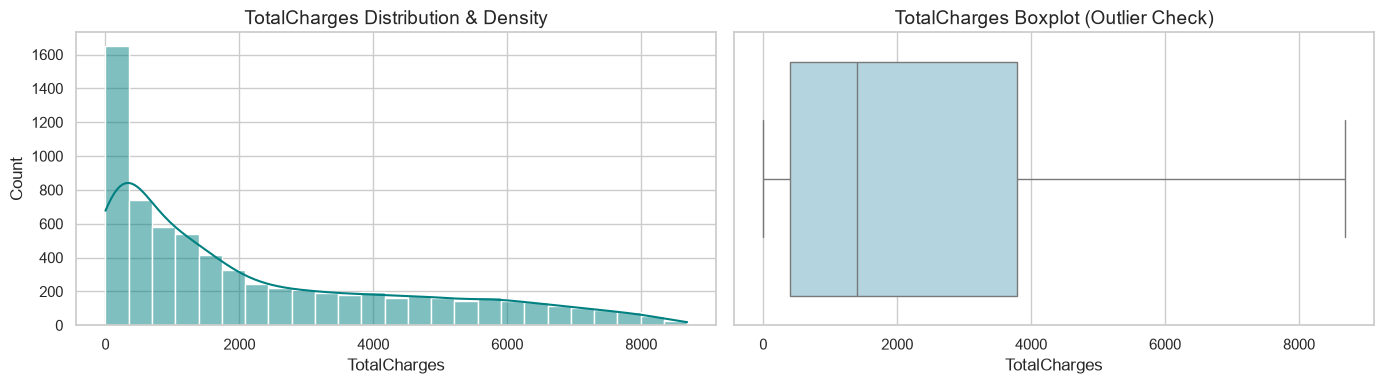

In [8]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    # 1. Histogram + KDE plot
    sns.histplot(df[col], kde=True, ax=axes[0], color='teal')
    axes[0].set_title(f'{col} Distribution & Density')
    
    # 2. Box Plot (To instantly detect outliers visually)
    sns.boxplot(x=df[col], ax=axes[1], color='lightblue')
    axes[1].set_title(f'{col} Boxplot (Outlier Check)')
    
    # Quantitative Check: Skewness Score
    skew_val = skew(df[col].dropna())
    print(f"Feature: {col:15} | Skewness: {skew_val:6.2f} -> ", end="")
    if abs(skew_val) < 0.5:
        print("Symmetric Distribution (Ideal)")
    elif 0.5 <= abs(skew_val) <= 1.0:
        print("Moderately Skewed")
    else:
        print("Highly Skewed (May require Log/Power Transformation later)")
    
    plt.tight_layout()
    plt.show()


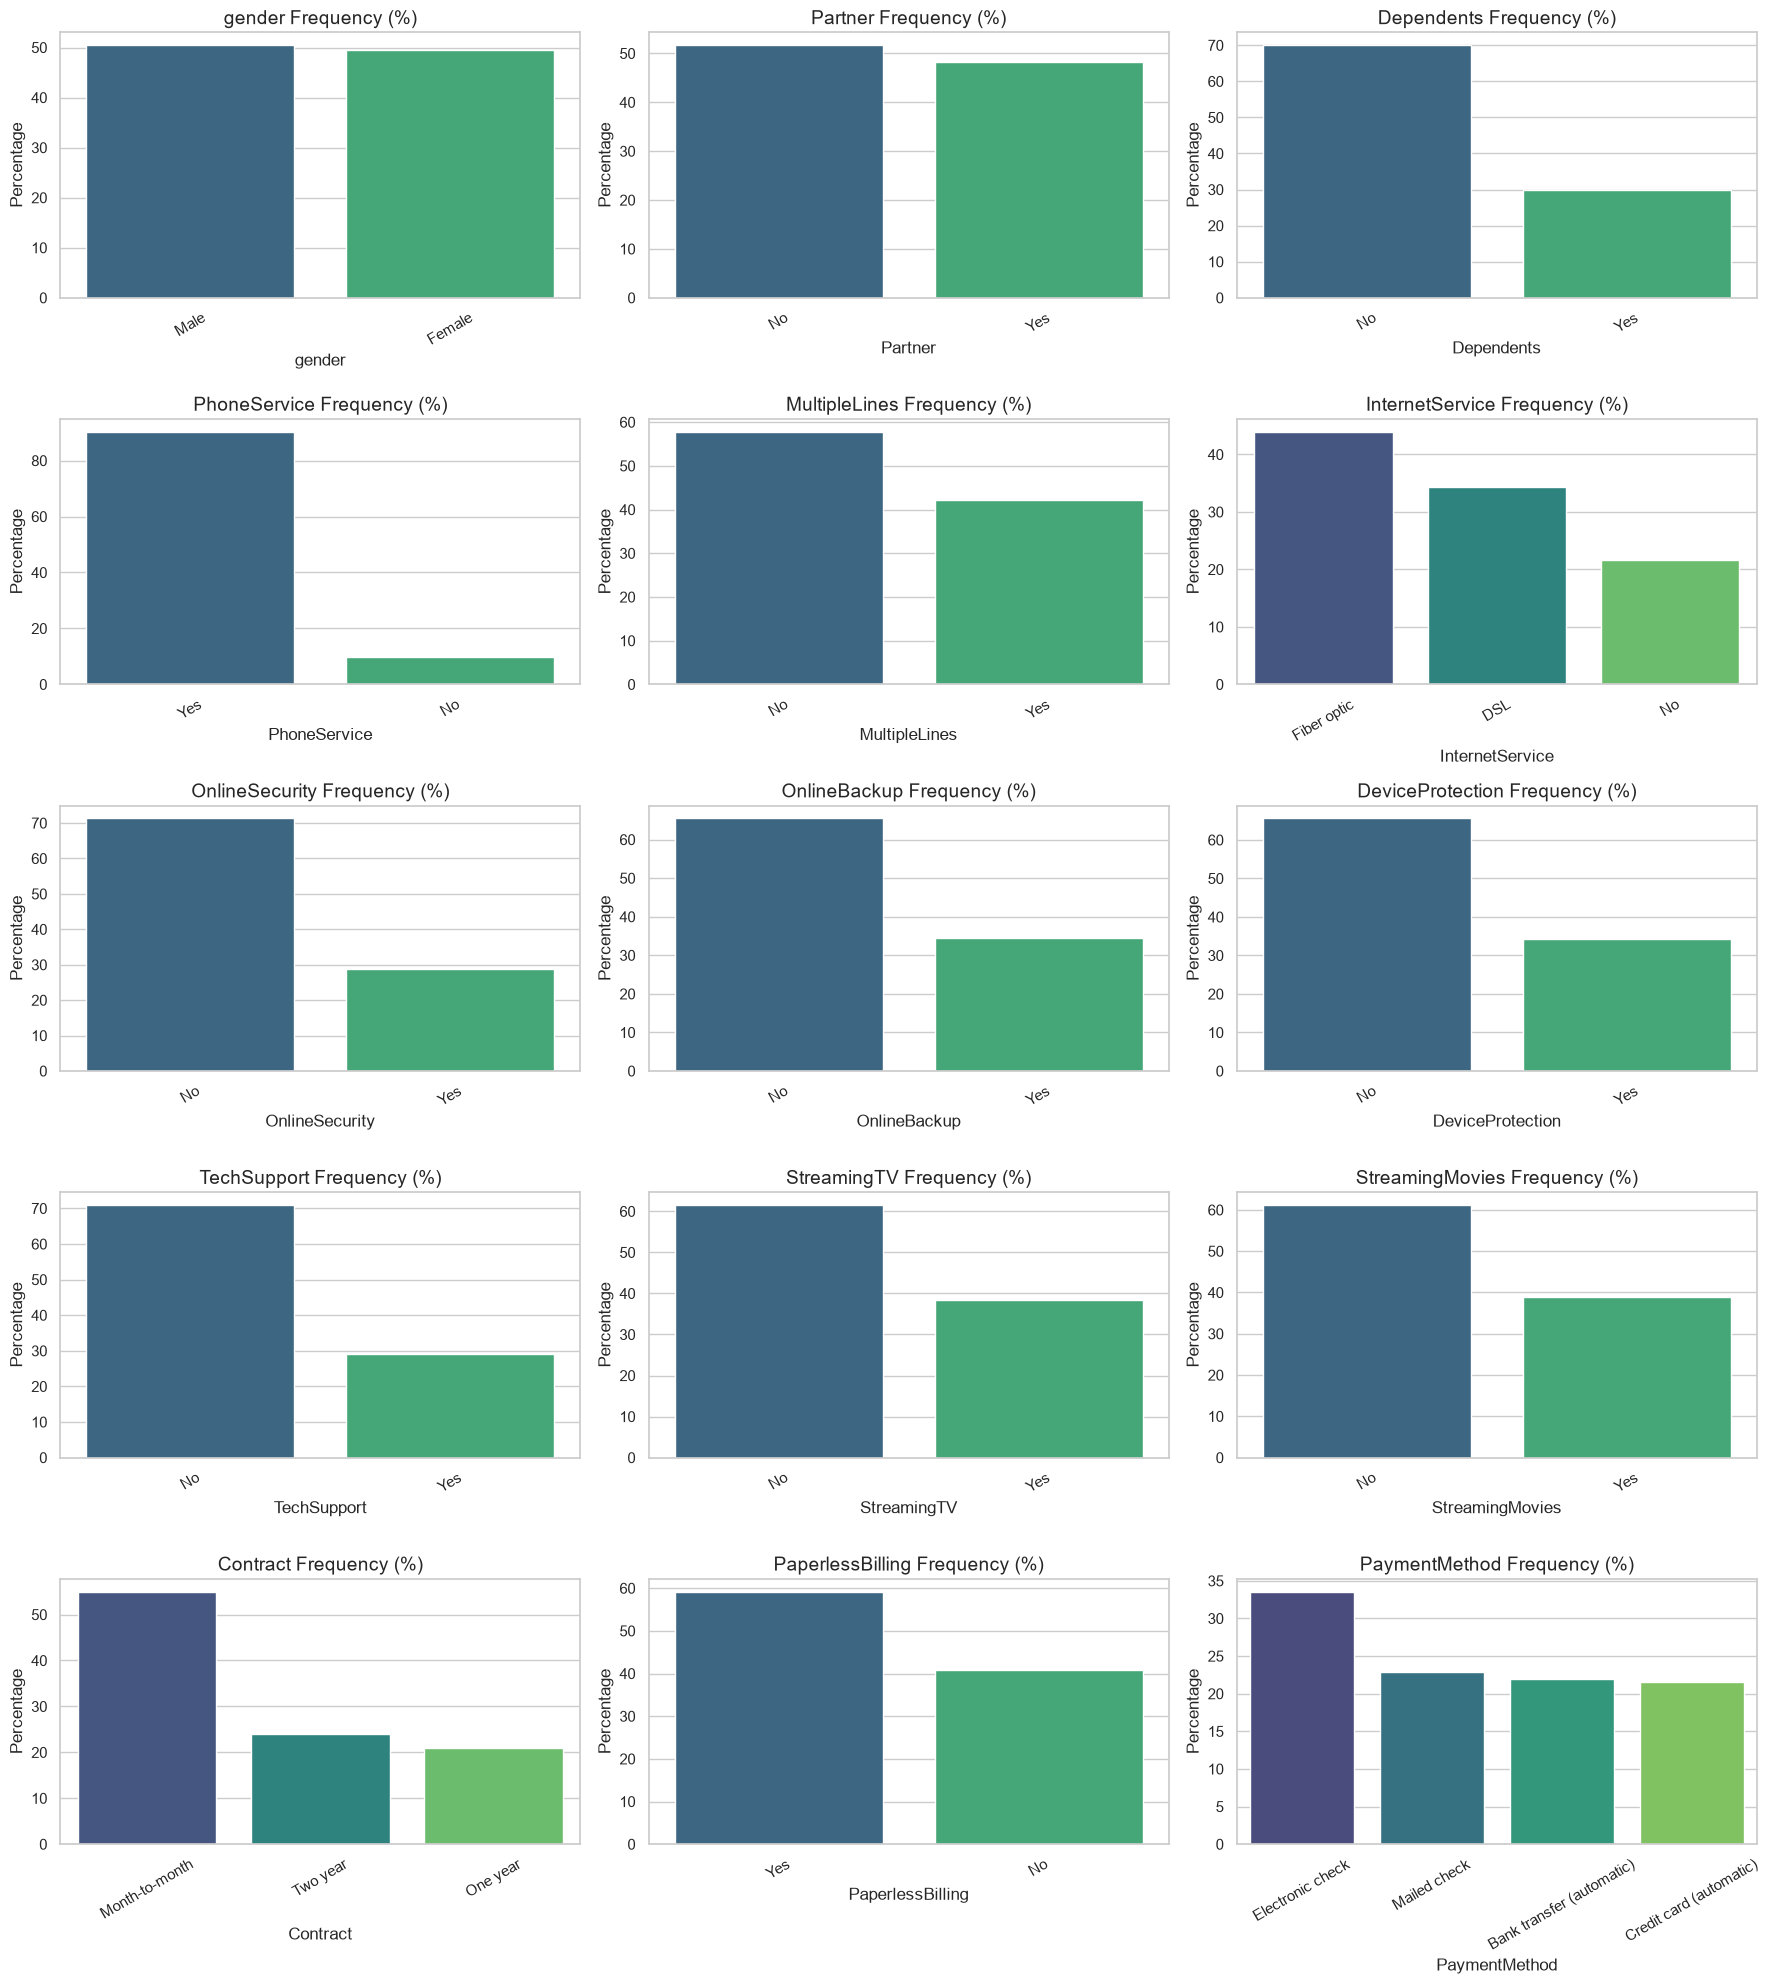

In [21]:
# Select object or string category features (excluding target if needed)
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Automated grid calculation based on column counts
n_cols = 3
n_rows = (len(cat_cols) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    # Normalized percentages instead of raw counts for clear business perspective
    counts = df[col].value_counts(normalize=True) * 100
    sns.barplot(x=counts.index, y=counts.values, ax=axes[i], palette='viridis')
    axes[i].set_title(f'{col} Frequency (%)')
    axes[i].set_ylabel('Percentage')
    axes[i].tick_params(axis='x', rotation=30)

# Unused axes cells ko clean up karein
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


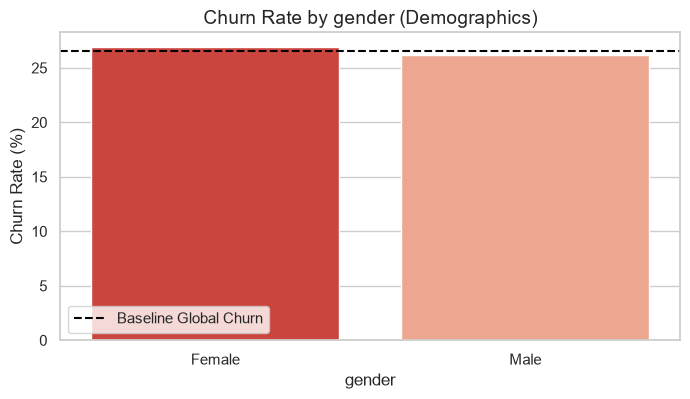

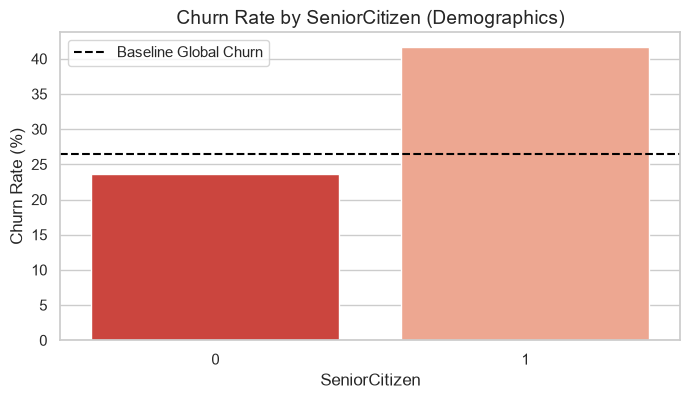

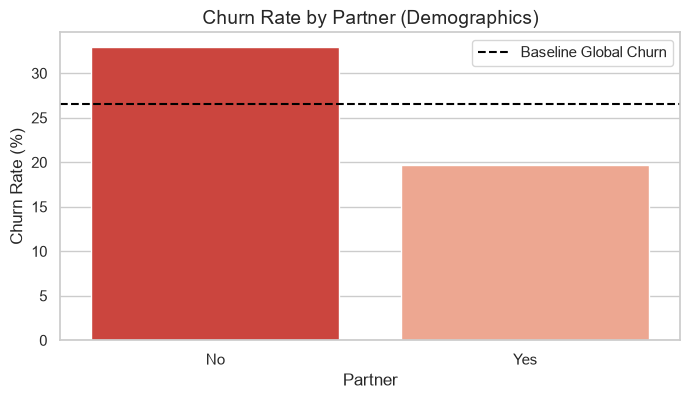

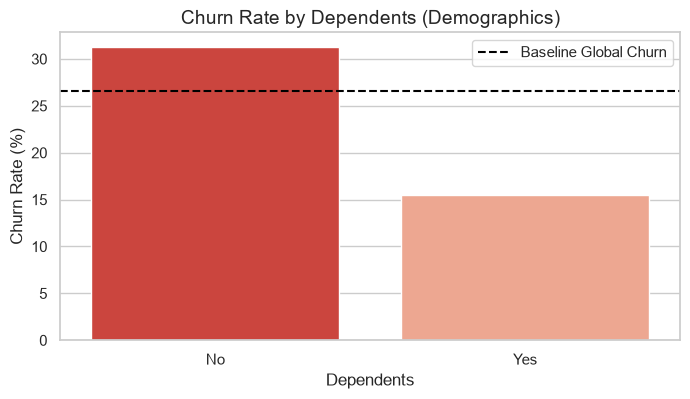

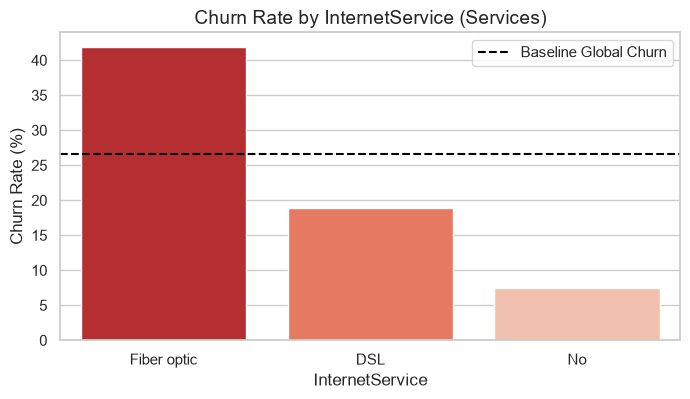

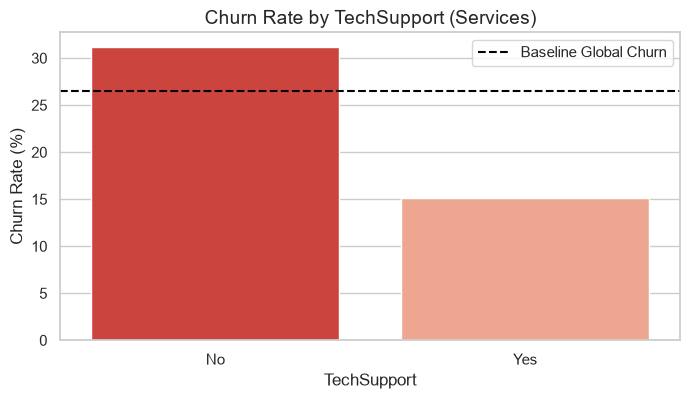

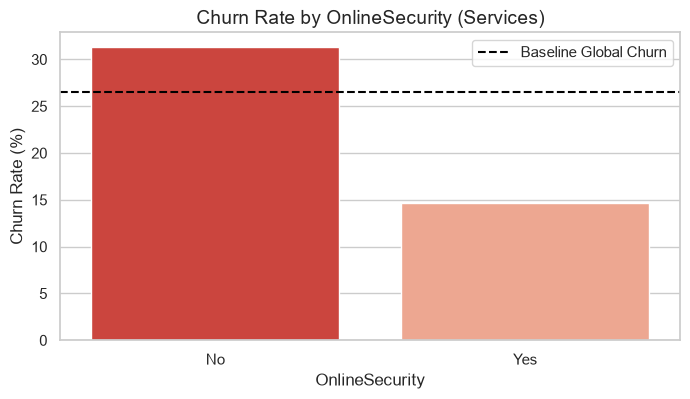

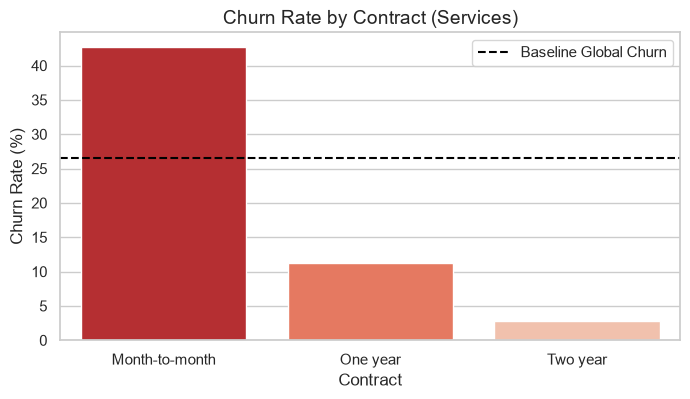

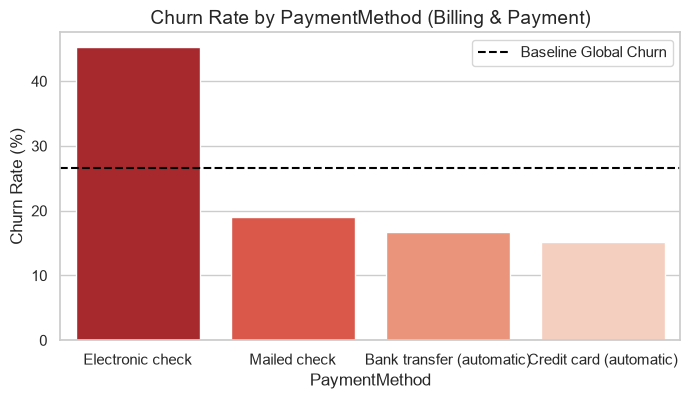

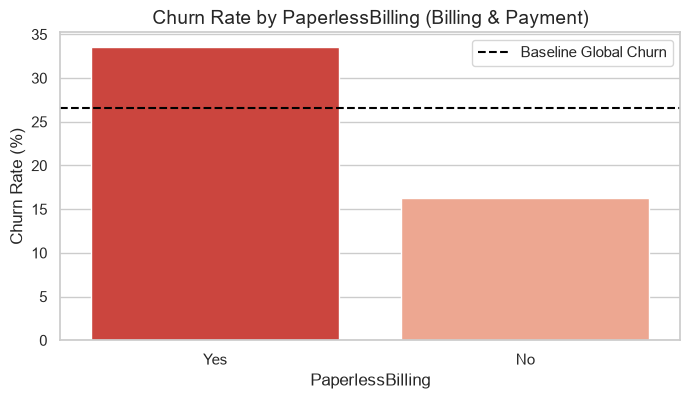

In [22]:
# Helper function to plot normalized churn rate per category feature
def plot_churn_relationship(feature_list, title_group):
    for col in feature_list:
        plt.figure(figsize=(8, 4))
        # Group by feature and calculate mean of Churn (since Churn is 1/0, mean == rate)
        churn_rate = df.groupby(col)['Churn'].mean() * 100
        churn_rate = churn_rate.reset_index().sort_values(by='Churn', ascending=False)
        
        # Purana Code (jis se warning aa rahi hai)
# sns.barplot(data=churn_rate, x=col, y='Churn', palette='Reds_r')

# Naya Code (Warning khatam karne ke liye)
        sns.barplot(data=churn_rate, x=col, y='Churn', hue=col, palette='Reds_r', legend=False)
        plt.axhline(y=df['Churn'].mean()*100, color='black', linestyle='--', label='Baseline Global Churn')
        plt.title(f'Churn Rate by {col} ({title_group})')
        plt.ylabel('Churn Rate (%)')
        plt.legend()
        plt.show()

# 1. Demographic Features
plot_churn_relationship(['gender', 'SeniorCitizen', 'Partner', 'Dependents'], 'Demographics')

# 2. Service Features
plot_churn_relationship(['InternetService', 'TechSupport', 'OnlineSecurity', 'Contract'], 'Services')

# 3. Payment Methods & Billing
plot_churn_relationship(['PaymentMethod', 'PaperlessBilling'], 'Billing & Payment')


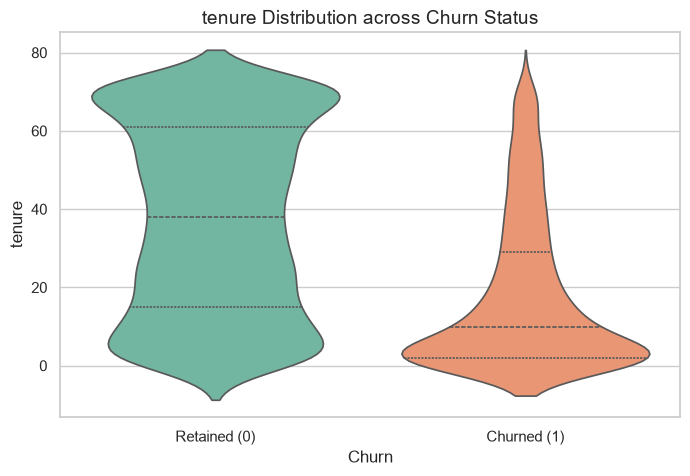

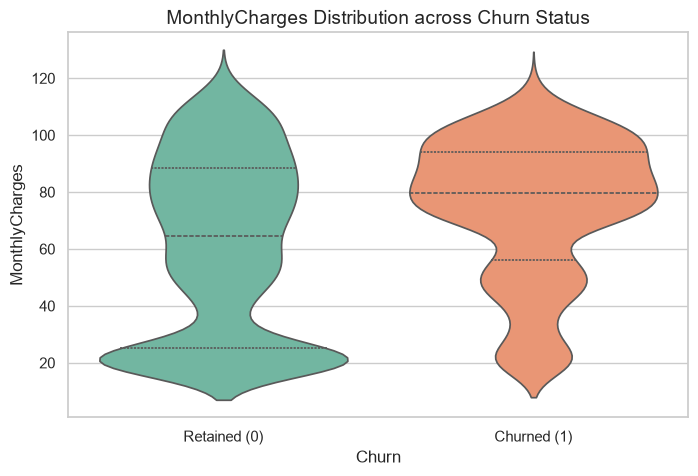

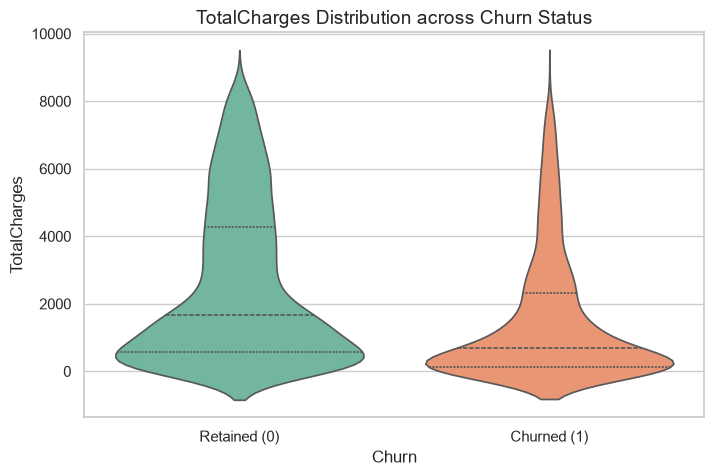

In [23]:
for col in num_cols:
    plt.figure(figsize=(8, 5))
    # Violin plot density aur outliers dono ek sath dikhata hai
    sns.violinplot(data=df, x='Churn', y=col, palette='Set2', inner="quartile")
    plt.title(f'{col} Distribution across Churn Status')
    plt.xticks([0, 1], ['Retained (0)', 'Churned (1)'])
    plt.show()


In [10]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

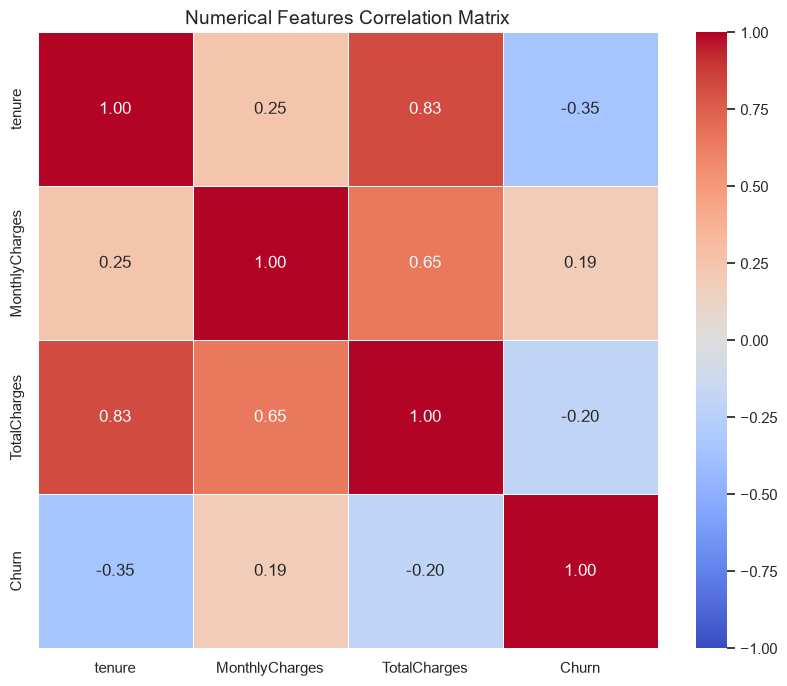

In [26]:
plt.figure(figsize=(10, 8))
# Sirf numerical parameters filter karein target vector ke sath
corr_matrix = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Numerical Features Correlation Matrix')
plt.show()


### 📌 Key Business Insights Summary

1. **Contract Type is the Strongest Churn Driver:** Month-to-month contracts ka churn rate baseline average se kafi zyada hai. One-year ya Two-year locked contracts wale customers high retention show karte hain.
2. **Early Tenure Vulnerability (The "Danger Zone"):** Churn status ke Violin plot se saaf zahir hai ke aksar churn karne wale customers pehle 1 se 6 mahine ke tenure loop me hain. Early onboarding tracking zaroori hai.
3. **Severe Tech-Support Dependency:** Jin customers ke paas `TechSupport=No` ya `OnlineSecurity=No` features hain, unka churn rate high high-risk pocket create kar raha hai. 
4. **Fiber Optic Pricing Friction:** `InternetService = Fiber Optic` ka churn rate standard DSL se zyada hai, aur yeh `MonthlyCharges` ke distribution spikes se match karta hai (High cost friction).
5. **High Multicollinearity detected via VIF:** `TotalCharges` ka VIF threshold (>5) se kaafi upar hai due to its strong linear dependency on `tenure` and `MonthlyCharges`. Feature selection ya tree-based robust algorithms use karne honge.
